In [2]:
def add_geometries(rainfall_events_all_df):
    # Get shape file
    regions_shp = "/scratch/hydro5/users/la17355/FUTURE-FLOOD/Results/Pluvial/v4/#ss/plots/most_exposed_events_visualisation/by_region/ukcp18-uk-land-region-hires.shp"
    regions_df = gpd.read_file(regions_shp)

    # Create columns on regions_df and catchments_df (CATCHMENTS) with each of their geometries
    regions_df["region_geometry"] = regions_df.geometry
    CATCHMENTS["catchment_geometry"] = CATCHMENTS.geometry

    # Convert events dataframe to geodataframe
    rainfall_events_all_df = gpd.GeoDataFrame(rainfall_events_all_df,
                            geometry=gpd.points_from_xy(rainfall_events_all_df["x_coord"], rainfall_events_all_df["y_coord"]), 
                                              crs=regions_df.crs)

    # Remove old sjoin columns if this dataframe has been joined before
    rainfall_events_all_df = rainfall_events_all_df.drop(
        columns=["index_right", "geo_region", "region_geometry", "HA_NAME", "catchment_geometry"], errors="ignore")

    # Join events dataframe with the regions geodata
    rainfall_events_all_df = gpd.sjoin(rainfall_events_all_df, regions_df[["geo_region", "region_geometry", "geometry"]],
        how="left", predicate="within")

    # Drop index_right before the next sjoin, or geopandas will error on the clash
    rainfall_events_all_df = rainfall_events_all_df.drop(columns=["index_right"], errors="ignore")

    # Join events dataframe with the catchments geodata
    rainfall_events_all_df = gpd.sjoin(rainfall_events_all_df, CATCHMENTS[["HA_NAME", "catchment_geometry", "geometry"]],
        how="left", predicate="within")

    rainfall_events_all_df = rainfall_events_all_df.drop(columns=["index_right"], errors="ignore")
    return rainfall_events_all_df

def national_and_regional_plot(df, region_col, region_list, value_col, group_col, group_values):
    colors = plt.cm.viridis(np.linspace(0, 1, len(group_values)))
    color_map = dict(zip(group_values, colors))

    def _plot(ax, sub, title):
        summary = sub.groupby([group_col, "intensity_bin"], observed=True)[value_col].mean().unstack()
        # summary =summary.iloc[:,:6]
        for g in group_values:
            if g in summary.index:
                ax.plot(summary.columns, summary.loc[g], marker="o", linewidth=4,
                         markersize=5, color=color_map[g], label=g)
        ax.set_title(title, fontsize=20)
        ax.spines[["top", "right"]].set_visible(False)
        ax.grid(axis="y", alpha=0.25)

    fig = plt.figure(figsize=(14, 14))
    n_regions = len(region_list)
    nrows = int(np.ceil(n_regions / 3)) + 1
    gs = gridspec.GridSpec(nrows, 3, height_ratios=[2] + [1]*(nrows-1), hspace=0.5, wspace=0.3)

    ax_national = fig.add_subplot(gs[0, :])
    _plot(ax_national, df, "National")

    for i, region in enumerate(region_list):
        row, col = divmod(i, 3)
        ax = fig.add_subplot(gs[row + 1, col], sharex=ax_national)
        _plot(ax, df[df[region_col] == region], region)

    handles, labels = ax_national.get_legend_handles_labels()
    fig.legend(handles, labels, title=group_col.title(), loc="upper center",
               bbox_to_anchor=(0.5, 0.95), ncol=len(group_values))
    # return fig


In [3]:
def plot_depth_by_intensity_for_timeslices(df):

    binned = (df.groupby(["geo_region", "period", "intensity_bin"],observed=True)["10cm_area"].agg(["mean", "median", "count"])
              .reset_index())

    ### Set colors
    colors = plt.cm.plasma(np.linspace(0, 1, 3))
    timeperiod_colors = dict(zip(reversed(np.unique(df['period'])), colors))

    # fig, axes = plt.subplots(nrows=int(np.ceil(len(region_order) / 3)),ncols=3,figsize=(15, 4 * int(np.ceil(len(region_order) / 3))))
    fig, axes = plt.subplots(5, 3, figsize=(12, 15), sharex=True, sharey=False)
    axes = axes.flatten()

    for ax, region in zip(axes, region_order):

        df = binned[binned["geo_region"] == region]

        for period, group in df.groupby("period",observed=False):

            ax.plot(group["intensity_bin"].astype(str),group["mean"],marker="o",label=period, color = timeperiod_colors[period])

        # ax.set_xlabel("Maximum precipitation")
        ax.set_ylabel("Mean 10cm area")
        ax.set_title(region)

        ax.legend()
        ax.tick_params(labelrotation=45)

    for j in range(len(region_order), 5 * 3):
        axes[j].axis("off")

    fig.suptitle("Changes to Mean per-event flooded area across intensity bins in the future climate");
    fig.tight_layout();

In [4]:
import pandas as pd
import matplotlib.pyplot as plt
import numpy as np
import matplotlib.gridspec as gridspec
import geopandas as gpd
import sys

sys.path.insert(1, '../../ProcessEvents')
from config import CATCHMENTS

## ------------------------------------------------------------ ###
### Get rainfall events
    And add extra variables
## ------------------------------------------------------------ ###

In [5]:
fp = f"/scratch/hydro4/users/kv25483/FutureFlood/Data/EventDetails_v4/all_catchments_with_topo.pkl"
rainfall_events_all_df = pd.read_pickle(fp)
rainfall_events_all_df = rainfall_events_all_df[rainfall_events_all_df['max_precip']<130].copy()
rainfall_events_all_df = rainfall_events_all_df[rainfall_events_all_df['start_year']>1991].copy()
rainfall_events_all_df["length"] = (rainfall_events_all_df["stop_idx"] - rainfall_events_all_df["start_idx"]).astype("float32")

rainfall_events_all_df['fu_at_peak_old_mm'] = rainfall_events_all_df['fu_at_peak_old']*1000
rainfall_events_all_df['HC_status'] = pd.cut(rainfall_events_all_df['hc_at_peak'],
    bins=[-float('inf'), 0.15, 1.1, 3, float('inf')],labels=['D', 'C', 'B', 'A'], right=False, include_lowest=True)

## ------------------------------------------------------------ ###
### Get spatial data and add regional geometries to rainfall data
## ------------------------------------------------------------ ###

In [6]:
rainfall_events_all_df  = add_geometries(rainfall_events_all_df)

## ------------------------------------------------------------ ###
### Add column defining which of 3 temporal periods an event is within
## ------------------------------------------------------------ ###

In [7]:
conditions = [rainfall_events_all_df["start_year"].between(1990, 2020),rainfall_events_all_df["start_year"].between(2020, 2050),
    rainfall_events_all_df["start_year"].between(2050, 2080),]
periods = ["1990–2020", "2020–2050", "2050–2080"]

rainfall_events_all_df["period"] = np.select(conditions, periods, default=None)

## ------------------------------------------------------------ ###
### Add column defining intensity bins
## ------------------------------------------------------------ ###

In [8]:
bins = [30, 35, 40, 45, 50, 60, 70, np.inf]
bins = [30,  40,  50, 60, 70, np.inf]
labels = [f"{bins[i]}–{bins[i+1]}" for i in range(len(bins)-2)] + ["100+"]
rainfall_events_all_df["intensity_bin"] = pd.cut(rainfall_events_all_df["max_precip"], bins=bins, labels=labels, include_lowest=True)

### Plots of the mean flooded area for events of different intensities

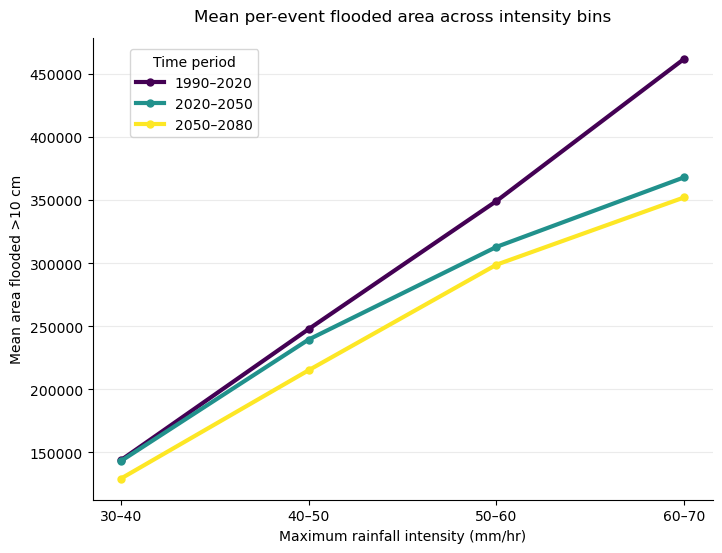

In [9]:
summary = (rainfall_events_all_df.groupby(["period", "intensity_bin"], observed=True)["10cm_volume"].mean().unstack())
summary =summary.iloc[:,:4]
colors = plt.cm.viridis(np.linspace(0, 1, len(periods)))

# Your plot currently reverses the region order, so make the same mapping
region_colors = dict(zip(reversed(periods), colors))

fig, ax = plt.subplots(figsize=(8, 6))

for choice, color in zip(periods, colors):
    ax.plot(summary.columns,summary.loc[choice],marker="o",linewidth=3,markersize=5,color=color,label=choice)

ax.set_xlabel("Maximum rainfall intensity (mm/hr)")
ax.set_ylabel("Mean area flooded >10 cm")
ax.set_title("Mean per-event flooded area across intensity bins",pad=12)

ax.grid(axis="y", alpha=0.25)
ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)
# ax.tick_params(axis="both", which="major", labelsize=12)

ax.legend(title="Time period",bbox_to_anchor=(0.05, 0.88),loc="center left",frameon=True);

In [10]:
region_order = ["North Scotland","East Scotland","West Scotland","North West England","North East England",
                "Yorkshire and Humber","West Midlands","East Midlands","East of England","Wales",
                "South West England","South East England","London"]

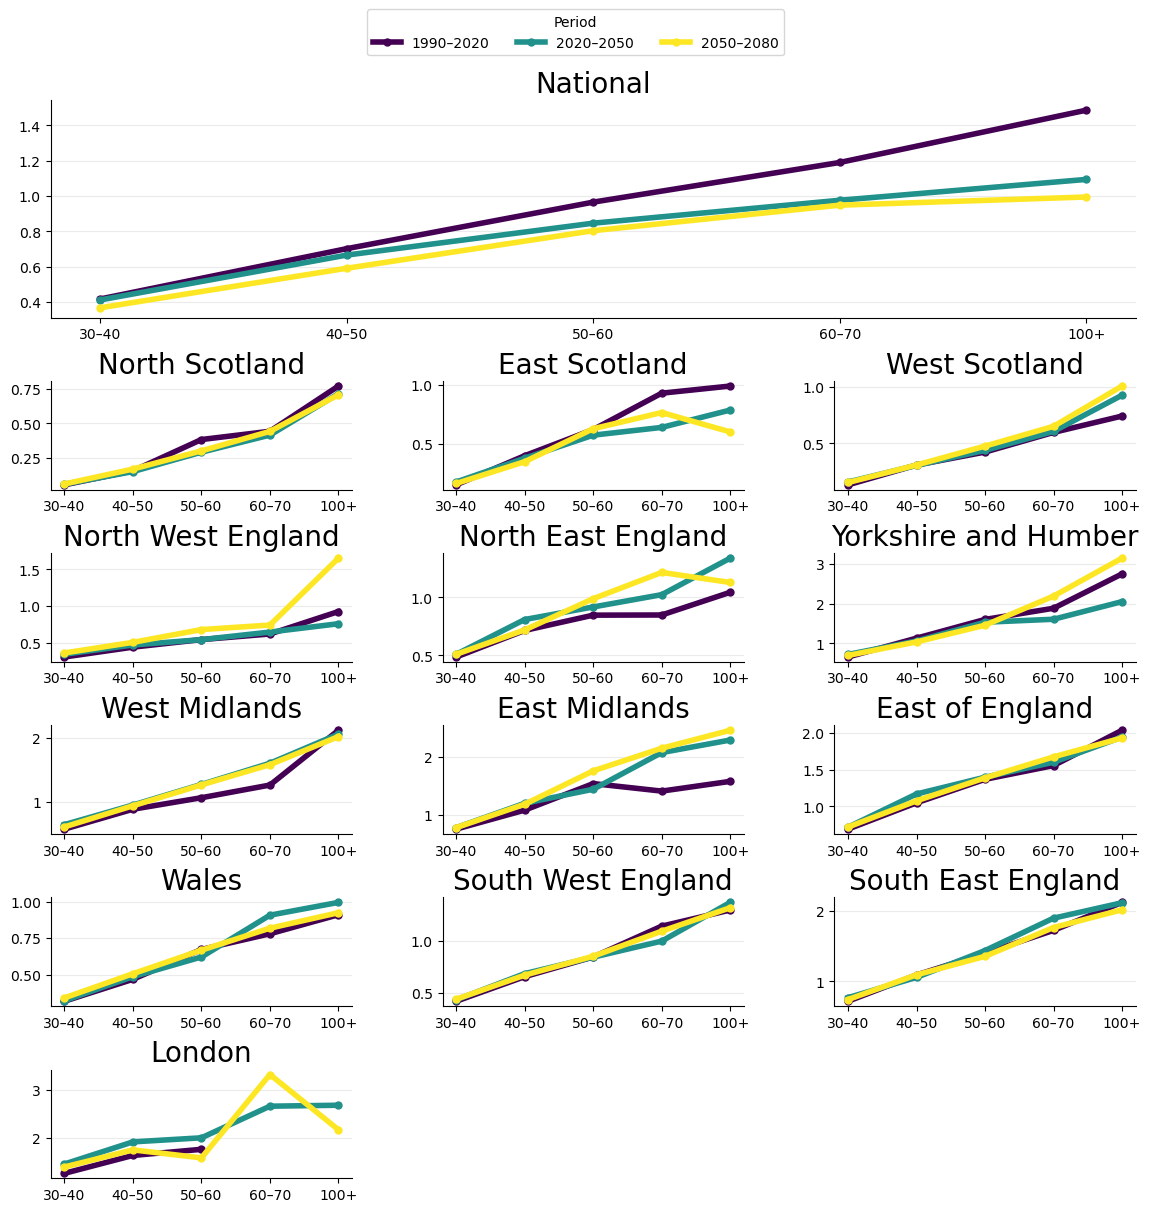

In [11]:
national_and_regional_plot(rainfall_events_all_df, 'geo_region', region_order, '10cm_area', "period", periods)

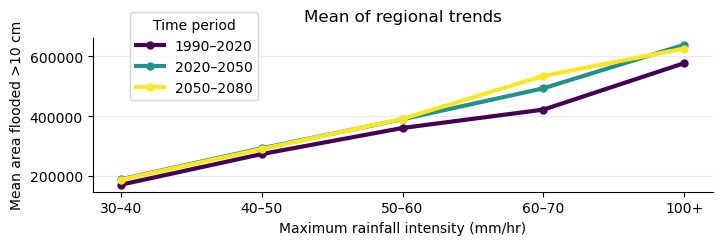

In [12]:
regional_means = (rainfall_events_all_df
    .groupby(["geo_region", "period", "intensity_bin"], observed=True)["10cm_volume"].mean().reset_index())
national_as_mean_of_regions = (
    regional_means.groupby(["period", "intensity_bin"], observed=True)["10cm_volume"].mean().unstack())

fig, ax = plt.subplots(figsize=(8, 2))

for choice, color in zip(periods, colors):
    ax.plot(national_as_mean_of_regions.columns,national_as_mean_of_regions.loc[choice],marker="o",linewidth=3,markersize=5,
            color=color,label=choice)

ax.set_xlabel("Maximum rainfall intensity (mm/hr)")
ax.set_ylabel("Mean area flooded >10 cm")
ax.set_title("Mean of regional trends",pad=12)

ax.grid(axis="y", alpha=0.25)
ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)
# ax.tick_params(axis="both", which="major", labelsize=12)

ax.legend(title="Time period",bbox_to_anchor=(0.05, 0.88),loc="center left",frameon=True);

## Split by event length

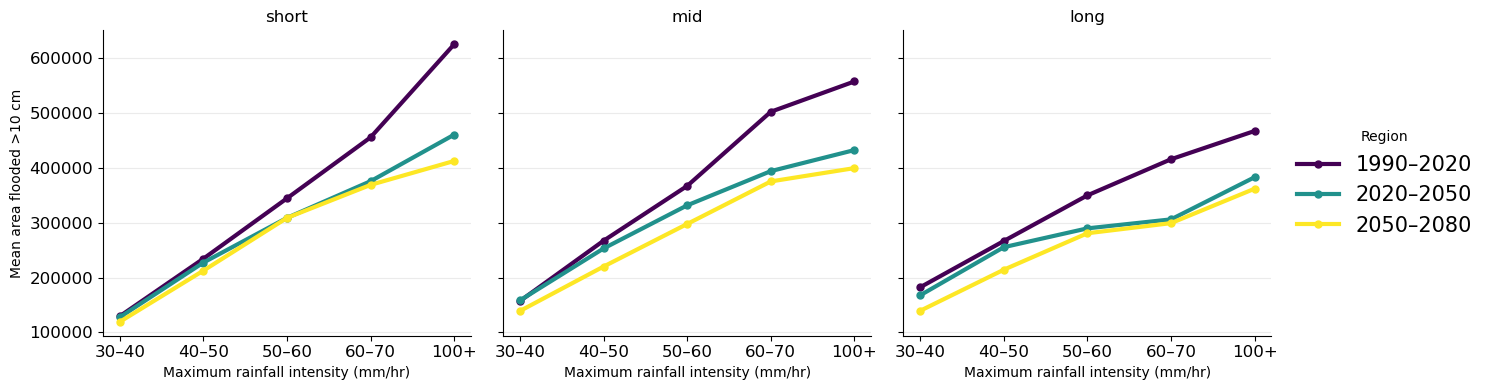

In [13]:
fig, ax = plt.subplots(ncols= 3, figsize=(15, 4), sharex=True, sharey=True)
ax_num=0
lengths = {'short': (0, 10),'mid': (10, 30), 'long':  (30, 200),}
colors = plt.cm.viridis(np.linspace(0, 1, len(periods)))

for label, (y0, y1) in lengths.items():
    mask = (rainfall_events_all_df['length_of_active_rain'] >= y0) & (rainfall_events_all_df['length_of_active_rain'] <= y1)
    df = rainfall_events_all_df.loc[mask]
    summary = (df.groupby(["period", "intensity_bin"], observed=True)["10cm_volume"].mean().unstack())
    
    # Your plot currently reverses the region order, so make the same mapping
    region_colors = dict(zip(periods, colors))

    for region, color in zip(periods, colors):
        ax[ax_num].plot(summary.columns,summary.loc[region],marker="o",linewidth=3,markersize=5,color=color,label=region)

    ax[ax_num].set_xlabel("Maximum rainfall intensity (mm/hr)")
    if ax_num == 0:
        ax[ax_num].set_ylabel("Mean area flooded >10 cm")
    #ax[ax_num].set_title("Mean per-event flooded area across intensity bins",
    #             fontsize=20, pad=12)
    
    ax[ax_num].set_title(label)
    ax[ax_num].grid(axis="y", alpha=0.25)
    ax[ax_num].spines["top"].set_visible(False)
    ax[ax_num].spines["right"].set_visible(False)
    ax[ax_num].tick_params(axis="both", which="major", labelsize=12)
    
    if ax_num == 2:
        ax[ax_num].legend(title="Region",bbox_to_anchor=(1.02, 0.5),loc="center left",frameon=False,fontsize=15)
    
    ax_num =ax_num+1
    
fig.tight_layout()

In [14]:
# event_counts = (
#     rainfall_events_all_df
#     .groupby(["period", "intensity_bin"], observed=True)
#     .size()
#     .unstack())
# print(event_counts)

# # And specifically: which regions have ANY events in the 100+ bin, by period?
# contributing_regions = (
#     rainfall_events_all_df[rainfall_events_all_df["intensity_bin"] == "100+"]
#     .groupby(["period", "geo_region"], observed=True)
#     .size()
#     .unstack(fill_value=0))
# contributing_regions

In [15]:
# for region in reversed(region_order):
#     this_region = rainfall_events_all_df[rainfall_events_all_df['geo_region']==region]
    
#     fig, ax = plt.subplots(ncols= 3, figsize=(15, 4), sharex=True, sharey=True)
#     ax_num=0
#     lengths = {'short': (0, 10),'mid': (10, 30), 'long':  (30, 200),}
#     colors = plt.cm.viridis(np.linspace(0, 1, len(periods)))

#     for label, (y0, y1) in lengths.items():
#         mask = (this_region['length_of_active_rain'] >= y0) & (this_region['length_of_active_rain'] <= y1)
#         df = this_region.loc[mask]
#         summary = (df.groupby(["period", "intensity_bin"], observed=True)["10cm_volume"].mean().unstack())

#         # Your plot currently reverses the region order, so make the same mapping
#         region_colors = dict(zip(periods, colors))

#         for choice, color in zip(periods, colors):
#             ax[ax_num].plot(summary.columns,summary.loc[choice],marker="o",linewidth=3,markersize=5,color=color,label=choice)

#         ax[ax_num].set_xlabel("Maximum rainfall intensity (mm/hr)")
#         if ax_num == 0:
#             ax[ax_num].set_ylabel("Mean area flooded >10 cm")
#         #ax[ax_num].set_title("Mean per-event flooded area across intensity bins",
#         #             fontsize=20, pad=12)

#         ax[ax_num].set_title(label)
#         ax[ax_num].grid(axis="y", alpha=0.25)
#         ax[ax_num].spines["top"].set_visible(False)
#         ax[ax_num].spines["right"].set_visible(False)
#         ax[ax_num].tick_params(axis="both", which="major", labelsize=12)

#         if ax_num == 2:
#             ax[ax_num].legend(title=region,bbox_to_anchor=(1.02, 0.5),loc="center left",frameon=False,fontsize=15)

#         ax_num =ax_num+1

#     fig.tight_layout()
#     fig.suptitle(region)

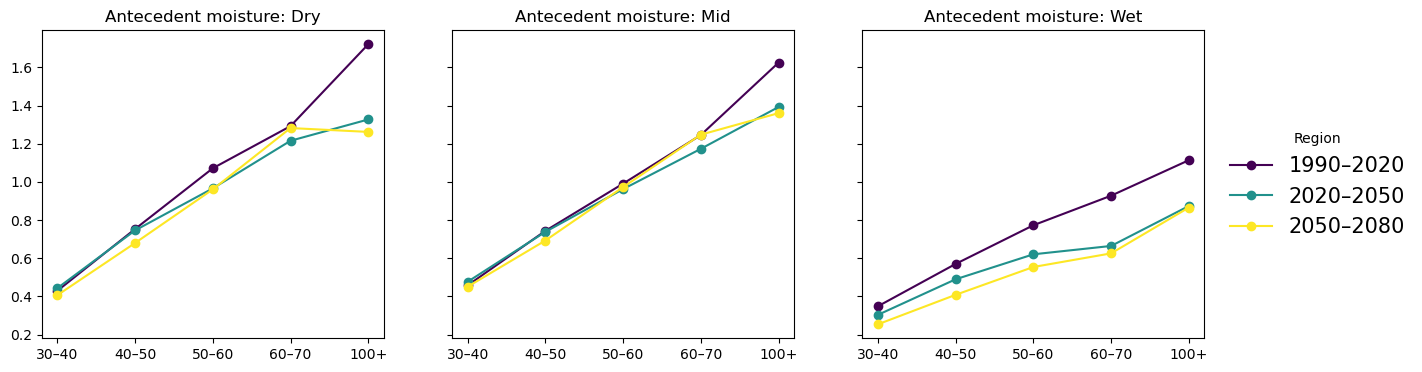

In [20]:
color_map = dict(zip(periods, colors))

rainfall_events_all_df["moisture_bin"] = pd.qcut(rainfall_events_all_df["mean_sm_2_before_event"], 3, labels=["Dry", "Mid", "Wet"])

fig, axes = plt.subplots(1, 3, figsize=(15, 4), sharey=True)
for ax, m_bin in zip(axes, ["Dry", "Mid", "Wet"]):
    sub = rainfall_events_all_df[rainfall_events_all_df["moisture_bin"] == m_bin]
    summary = sub.groupby(["period", "intensity_bin"], observed=True)["10cm_area"].mean().unstack()
    for period in periods:
        if period in summary.index:
            ax.plot(summary.columns, summary.loc[period], marker="o", color=color_map[period], label=period)
    ax.set_title(f"Antecedent moisture: {m_bin}")
    if m_bin == 'Wet':
        ax.legend(title="Region",bbox_to_anchor=(1.02, 0.5),loc="center left",frameon=False,fontsize=15)

In [179]:
target_bin = '30–40'
season_mix = (rainfall_events_all_df
    .groupby(['period', 'season'], observed=True).size()
    .groupby(level=0).apply(lambda x: x / x.sum())
    .unstack())

,season,DJF,JJA,MAM,SON
period,period,,,,
1990–2020,1990–2020,0.012345,0.782753,0.043879,0.161023
2020–2050,2020–2050,0.046529,0.657871,0.066478,0.229122
2050–2080,2050–2080,0.081989,0.557881,0.072999,0.287130


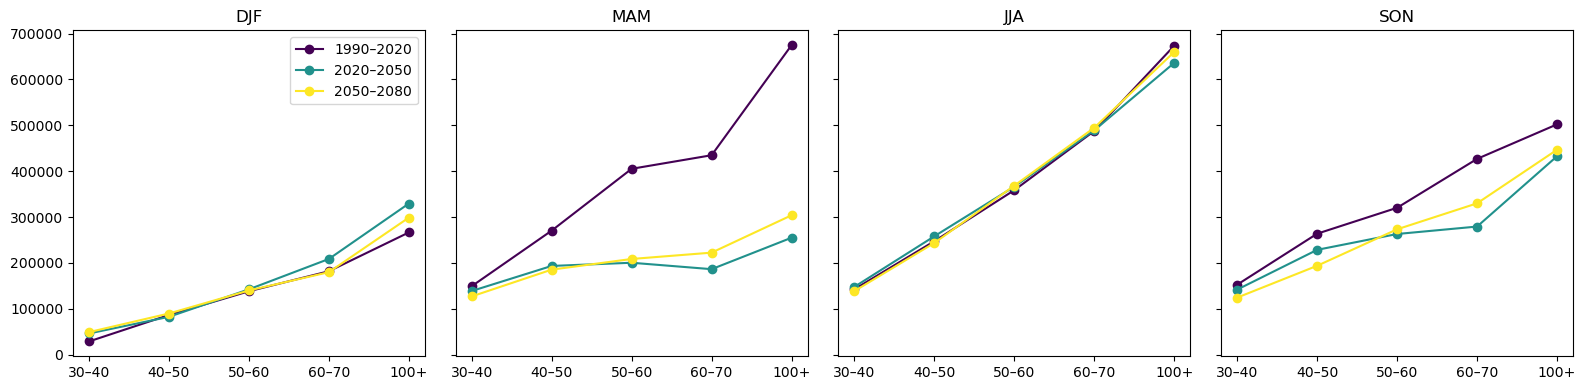

In [159]:
fig, axes = plt.subplots(1, 4, figsize=(16,4), sharey=True)
for ax, season in zip(axes, ['DJF','MAM','JJA','SON']):
    sub = rainfall_events_all_df[rainfall_events_all_df['season'] == season]
    summary = sub.groupby(["period", "intensity_bin"], observed=True)["10cm_volume"].mean().unstack()
    for choice in periods:
        if choice in summary.index:
            ax.plot(summary.columns, summary.loc[choice], marker="o", color=color_map[choice], label=choice)
    ax.set_title(season)
axes[0].legend()
plt.tight_layout()
plt.show()

In [167]:
from scipy import stats

trend_results = []
period_numeric = {'1990–2020': 0, '2020–2050': 1, '2050–2080': 2}  # adjust to your actual labels

for region in region_order:
    # Get data just this region
    sub = rainfall_events_all_df[rainfall_events_all_df['geo_region'] == region]
    # For each intensity bin
    for ibin in sub['intensity_bin'].cat.categories:
        bsub = sub[sub['intensity_bin'] == ibin].copy()
        bsub['period_num'] = bsub['period'].map(period_numeric)
        if bsub['period_num'].nunique() < 2:
            continue
        slope, intercept, r, p, se = stats.linregress(bsub['period_num'], bsub['10cm_volume'])
        trend_results.append({'region': region, 'intensity_bin': ibin, 'slope': slope, 'p_value': p, "se": se})

trend_df = pd.DataFrame(trend_results)
# trend_df[trend_df['p_value'] < 0.05]  # which region/bin combinations show a credible trend

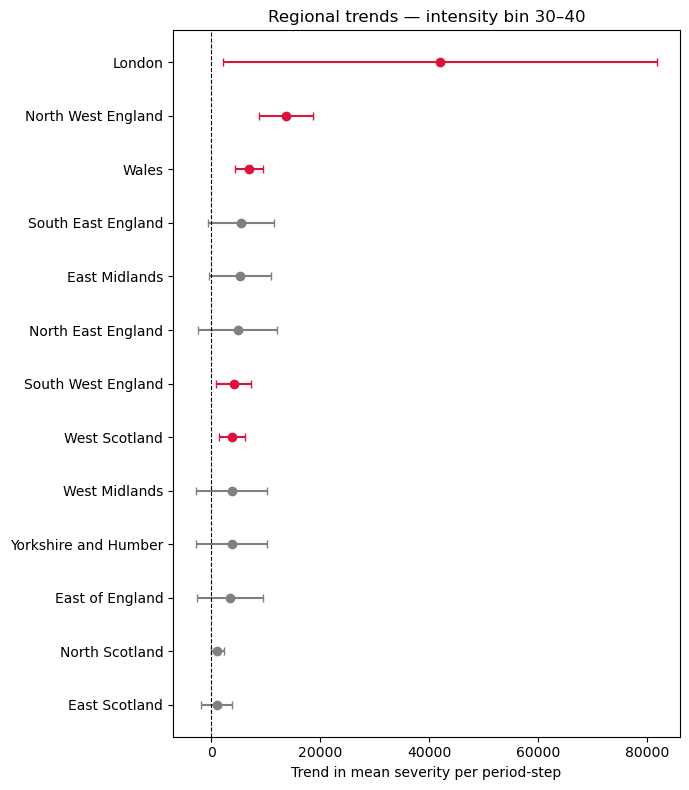

In [164]:
fig, ax = plt.subplots(figsize=(7, 8))

sub = trend_df[trend_df['intensity_bin'] == target_bin].sort_values('slope').reset_index(drop=True)
y_pos = np.arange(len(sub))

for i, row in sub.iterrows():
    color = 'crimson' if row['p_value'] < 0.05 else 'grey'
    ax.errorbar(row['slope'], y_pos[i], xerr=1.96*row['se'], fmt='o', capsize=3, color=color)

ax.axvline(0, color='k', lw=0.8, linestyle='--')
ax.set_yticks(y_pos)
ax.set_yticklabels(sub['region'])
ax.set_xlabel('Trend in mean severity per period-step')
ax.set_title(f'Regional trends — intensity bin {target_bin}')
plt.tight_layout()
plt.show()

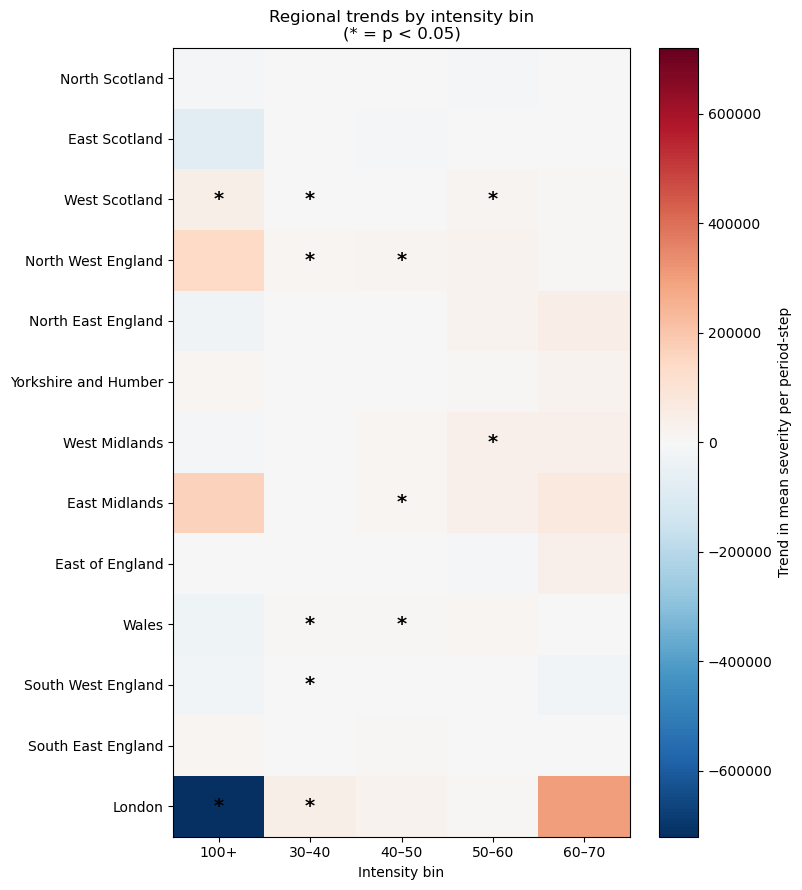

In [165]:
# Pivot trend_df into a region x intensity_bin grid of slopes
slope_grid = trend_df.pivot(index='region', columns='intensity_bin', values='slope')
pval_grid = trend_df.pivot(index='region', columns='intensity_bin', values='p_value')

# Order rows consistently (e.g. by overall mean slope, or your existing region_order)
slope_grid = slope_grid.reindex(region_order)
pval_grid = pval_grid.reindex(region_order)

fig, ax = plt.subplots(figsize=(8, 9))

vmax = np.nanmax(np.abs(slope_grid.values))
im = ax.imshow(slope_grid.values, cmap='RdBu_r', vmin=-vmax, vmax=vmax, aspect='auto')

# Mark significant cells with an asterisk
for i in range(slope_grid.shape[0]):
    for j in range(slope_grid.shape[1]):
        p = pval_grid.values[i, j]
        if not np.isnan(p) and p < 0.05:
            ax.text(j, i, '*', ha='center', va='center', color='black', fontsize=14, fontweight='bold')

ax.set_xticks(range(len(slope_grid.columns)))
ax.set_xticklabels(slope_grid.columns)
ax.set_yticks(range(len(slope_grid.index)))
ax.set_yticklabels(slope_grid.index)
ax.set_xlabel('Intensity bin')
plt.colorbar(im, ax=ax, label='Trend in mean severity per period-step')
ax.set_title('Regional trends by intensity bin\n(* = p < 0.05)')
plt.tight_layout()
plt.show()

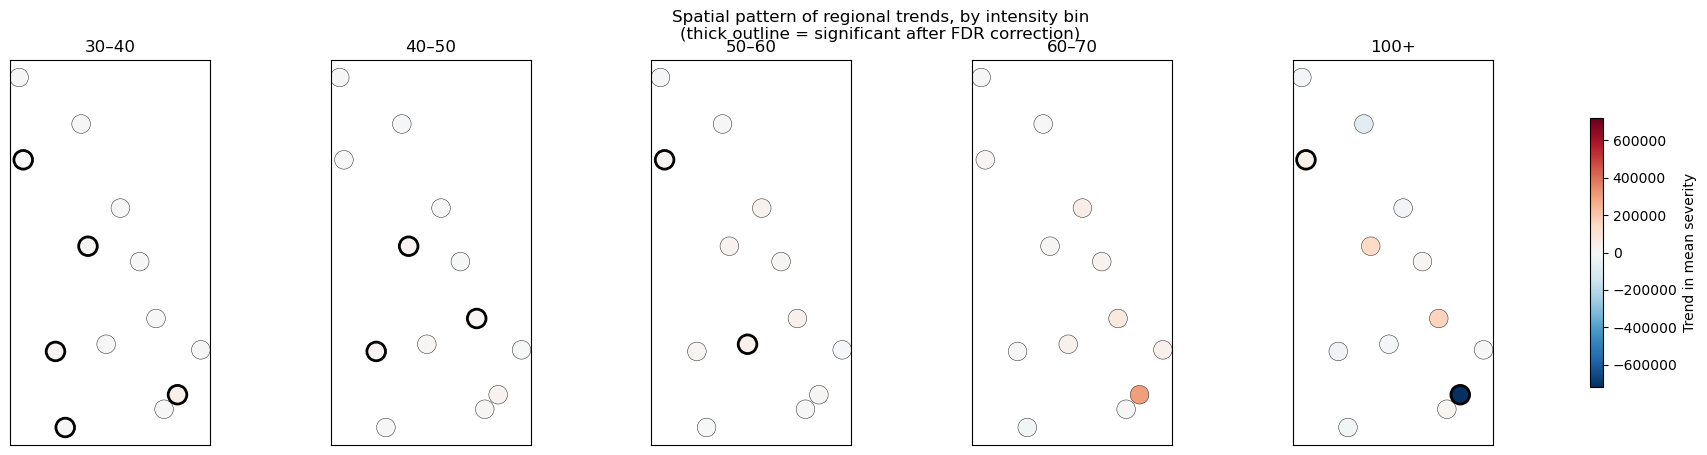

In [166]:
# Reconcile column naming between trend_df ('region') and the main dataframe ('geo_region')
region_centroids = (
    rainfall_events_all_df.groupby('geo_region')[['x_coord', 'y_coord']]
    .mean().reset_index().rename(columns={'geo_region': 'region'}))

trend_with_coords = trend_df.merge(region_centroids, on='region', how='left')

intensity_bins_available = trend_with_coords['intensity_bin'].cat.categories if hasattr(trend_with_coords['intensity_bin'], 'cat') else trend_with_coords['intensity_bin'].unique()

fig, axes = plt.subplots(1, len(intensity_bins_available), figsize=(5*len(intensity_bins_available), 5), sharex=True, sharey=True)

vmax = np.nanmax(np.abs(trend_with_coords['slope']))

for ax, ibin in zip(axes, intensity_bins_available):
    sub = trend_with_coords[trend_with_coords['intensity_bin'] == ibin]
    edgewidths = np.where(sub['p_value'] < 0.05, 2.0, 0.3)  # use p_adjusted if you've applied the FDR correction

    sc = ax.scatter(sub['x_coord'], sub['y_coord'], c=sub['slope'], cmap='RdBu_r',
                     vmin=-vmax, vmax=vmax, s=180, edgecolor='k', linewidth=edgewidths)
    ax.set_title(ibin)
    ax.set_aspect('equal')
    ax.set_xticks([])
    ax.set_yticks([])

fig.colorbar(sc, ax=axes, label='Trend in mean severity', shrink=0.7)
fig.suptitle('Spatial pattern of regional trends, by intensity bin\n(thick outline = significant after FDR correction)')
plt.show()